# 06_o3 — Equation discovery (Medellín, o3 target)

Mirrors Bogotá's equation-discovery notebook exactly: PySR + pySINDy on the no-lag
feature selection from notebook 05_o3, a single-feature linear baseline, and a
physical-plausibility (monotonicity) check on the discovered equations.


In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path("/path/to/project")
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression

DATA_DIR = PROJECT_ROOT / "Data" / "processed" / "colombia" / "medellin"
FIG_DIR = PROJECT_ROOT / "Scripts" / "colombia" / "medellin" / "figures"

df = pd.read_parquet(DATA_DIR / "medellin_o3_master_dataset.parquet")
df = df.dropna(subset=['o3']).reset_index(drop=True)

with open(DATA_DIR / "medellin_o3_feature_selection.json") as f:
    selection = json.load(f)

features = selection['selected_no_lag']
print("Using features:", features)

data = df.dropna(subset=features + ['o3']).reset_index(drop=True)
X = data[features].to_numpy()
y = data['o3'].to_numpy()
print(data.shape)


Using features: ['radiation_station', 'pm25_lag1', 'wind_speed', 'no_sisaire', 'no2', 'pmc_lag2']
(1389, 261)


## Diagnostic helpers (defined here, not imported -- edit freely)

Colormap, response-surface, predicted-vs-observed, and term-decomposition plotting all
live directly in this notebook so styling (colors, figure layout, etc.) can be tweaked
in place without editing a separate shared file. Only the core LOYO-CV/metrics math
stays in `common/` since that's pipeline infrastructure, not something you'd usually
want to change per-plot.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde
import sympy

# ---- Your preferred palette -- edit these hex stops to change every plot's colors ----
USER_CMAP = LinearSegmentedColormap.from_list(
    "user_pref",
    ["#ffffff", "#3b4cc0", "#6a2c91", "#c2298a", "#e8611c", "#d62728"],
)


def stratified_error_table(y_true, y_pred, unit=""):
    """RMSE/Mean Bias/NMB within low (<=p10), middle (p40-p60) and high (>=p90) bands
    of the OBSERVED value -- reveals asymmetric error (e.g. underprediction of the
    worst days) that a single aggregate RMSE/R2 hides entirely."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    p10, p40, p60, p90 = np.percentile(y_true, [10, 40, 60, 90])
    bins = {
        "low (<=p10)": y_true <= p10,
        "middle (p40-p60)": (y_true >= p40) & (y_true <= p60),
        "high (>=p90)": y_true >= p90,
    }
    rows = []
    for name, mask in bins.items():
        yt, yp = y_true[mask], y_pred[mask]
        mb = float(np.mean(yp - yt))
        rows.append({
            "band": name, "n": int(mask.sum()),
            "obs_mean": float(np.mean(yt)), "pred_mean": float(np.mean(yp)),
            "rmse": float(np.sqrt(np.mean((yp - yt) ** 2))), "mb": mb,
            "nmb_pct": 100.0 * mb / np.mean(yt),
        })
    df = pd.DataFrame(rows).set_index("band")
    print(f"Stratified error by observed-value band{f' ({unit})' if unit else ''}:")
    print(df.round(2).to_string())
    return df


def hit_far_table(y_true, y_pred, thresholds_pct=(75, 90, 95)):
    """Categorical (HIT/FAR/CSI) forecast verification: event = exceeds the Nth
    percentile of observed values. Hit rate (POD) = TP/(TP+FN); FAR = FP/(TP+FP);
    CSI = TP/(TP+FN+FP)."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    rows = []
    for pct in thresholds_pct:
        thresh = np.percentile(y_true, pct)
        obs_event = y_true >= thresh
        pred_event = y_pred >= thresh
        tp = int(np.sum(obs_event & pred_event))
        fn = int(np.sum(obs_event & ~pred_event))
        fp = int(np.sum(~obs_event & pred_event))
        tn = int(np.sum(~obs_event & ~pred_event))
        hit_rate = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
        far = fp / (tp + fp) if (tp + fp) > 0 else float("nan")
        csi = tp / (tp + fn + fp) if (tp + fn + fp) > 0 else float("nan")
        rows.append({
            "threshold_pct": pct, "threshold_value": thresh, "n_events": tp + fn,
            "TP": tp, "FN": fn, "FP": fp, "TN": tn,
            "hit_rate": hit_rate, "far": far, "csi": csi,
        })
    df = pd.DataFrame(rows).set_index("threshold_pct")
    print("Categorical (HIT/FAR/CSI) verification, event = exceeds observed Nth percentile:")
    print(df.round(3).to_string())
    return df


def sindy_term_contributions(coef_model, lib_X, lib_names, y_true, title=""):
    """Per-term decomposition of a fitted pySINDy (STLSQ) model: the polynomial library
    form is already a literal sum of coefficient*term, so each term's contribution to
    the prediction can be isolated directly. A term's coefficient sign can differ from
    its own raw correlation with the target when terms are collinear -- flag it, don't
    silently trust the coefficient as "the" physical sign."""
    coefs = coef_model.coef_.ravel()
    active = [(n, c, lib_X[:, i]) for i, (n, c) in enumerate(zip(lib_names, coefs)) if abs(c) > 1e-10]
    rows = []
    for n, c, vals in active:
        contrib = c * vals
        rows.append({
            "term": n, "coef": c,
            "mean_abs_contribution": float(np.mean(np.abs(contrib))),
            "std_contribution": float(np.std(contrib)),
            "corr_with_target": float(np.corrcoef(contrib, y_true)[0, 1]) if np.std(contrib) > 0 else np.nan,
        })
    summary = pd.DataFrame(rows).sort_values("mean_abs_contribution", ascending=False)
    print(f"Per-term contribution breakdown ({len(active)} active terms):")
    print(summary.round(3).to_string(index=False))
    fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(active))))
    ordered = summary.sort_values("mean_abs_contribution")
    ax.barh(ordered["term"], ordered["mean_abs_contribution"])
    ax.set_xlabel("Mean |contribution| to prediction")
    ax.set_title(title or "Per-term contribution magnitude")
    fig.tight_layout()
    return summary, fig


def pysr_term_contributions(equation_str, features, data, y_true, title=""):
    """Per-term decomposition of a PySR equation via sympy's Add.make_args (handles
    nesting correctly, unlike a naive string split on '+'). Complements
    sindy_term_contributions: pySINDy's polynomial library can structurally miss a real
    but nonlinearly-related predictor (e.g. a right-skewed fire-hotspot count needing a
    sqrt transform) -- a PySR search that already found and kept such a term won't have
    that blind spot, so report both rather than trusting whichever is sparser."""
    local_dict = {f: sympy.Symbol(f) for f in features}
    expr = sympy.sympify(equation_str, locals=local_dict)
    top_level_terms = sympy.Add.make_args(expr)
    rows = []
    for term_expr in top_level_terms:
        free_syms = [str(s) for s in term_expr.free_symbols]
        term_name = str(term_expr) if free_syms else f"const={float(term_expr):.4g}"
        if free_syms:
            fn = sympy.lambdify([local_dict[f] for f in features if f in free_syms], term_expr, "numpy")
            vals = fn(*[data[f].to_numpy() for f in features if f in free_syms])
            vals = np.broadcast_to(np.asarray(vals, dtype=float), (len(data),))
        else:
            vals = np.full(len(data), float(term_expr))
        rows.append({
            "term": term_name,
            "mean_abs_contribution": float(np.mean(np.abs(vals))),
            "std_contribution": float(np.std(vals)),
            "corr_with_target": float(np.corrcoef(vals, y_true)[0, 1]) if np.std(vals) > 0 else np.nan,
        })
    summary = pd.DataFrame(rows).sort_values("mean_abs_contribution", ascending=False)
    print(f"PySR equation per-term contribution ({len(top_level_terms)} top-level terms):")
    print(summary.round(3).to_string(index=False))
    fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(top_level_terms))))
    ordered = summary.sort_values("mean_abs_contribution")
    ax.barh(ordered["term"], ordered["mean_abs_contribution"])
    ax.set_xlabel("Mean |contribution| to prediction")
    ax.set_title(title or "PySR equation: per-term contribution magnitude")
    fig.tight_layout()
    return summary, fig


def check_features_used(equation_str, features):
    """Which selected features are actually present anywhere in a PySR equation string
    (any nesting depth, via sympy's free_symbols) -- prints features that got selected
    by SFS but then dropped entirely from the final discovered equation."""
    local_dict = {f: sympy.Symbol(f) for f in features}
    expr = sympy.sympify(equation_str, locals=local_dict)
    used = {str(s) for s in expr.free_symbols}
    missing = [f for f in features if f not in used]
    if missing:
        print(f"Selected but NOT present in this equation: {missing}")
    else:
        print("All selected features appear somewhere in this equation.")
    return missing


def predicted_vs_observed(predictions, unit="", title="", cmap=USER_CMAP):
    """Mirrors Abramian et al. (2025, npj Climate and Atmospheric Science) Fig. 3A/B:
    density-colored 1:1 scatter, one panel per model, with the 1:1 line drawn. Point
    color = local density (Gaussian KDE) so the dense "typical day" cloud doesn't drown
    out the sparser, more policy-relevant tail.

    ``predictions``: {model_name: (y_true, y_pred)}."""
    n_panels = len(predictions)
    fig, axes = plt.subplots(1, n_panels, figsize=(5.5 * n_panels, 5.2), squeeze=False)
    axes = axes[0]
    all_vals = np.concatenate([np.concatenate([yt, yp]) for yt, yp in predictions.values()])
    lo, hi = np.percentile(all_vals, [0.5, 99.5])
    for ax, (name, (y_true, y_pred)) in zip(axes, predictions.items()):
        y_true = np.asarray(y_true)
        y_pred = np.asarray(y_pred)
        xy = np.vstack([y_true, y_pred])
        density = gaussian_kde(xy)(xy)
        order = density.argsort()
        sc = ax.scatter(y_true[order], y_pred[order], c=density[order], s=10, cmap=cmap)
        ax.plot([lo, hi], [lo, hi], "k-", lw=1, label="1:1")
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect("equal")
        r2 = 1 - np.sum((y_pred - y_true) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2)
        ax.set_title(f"{name}\nR2={r2:.3f}")
        ax.set_xlabel(f"Observed{f' ({unit})' if unit else ''}")
        ax.set_ylabel(f"Predicted{f' ({unit})' if unit else ''}")
        ax.legend(loc="upper left", fontsize=8)
        fig.colorbar(sc, ax=ax, label="density")
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig


def response_surface_comparison(data, features, target, predict_fns, feature_x=None,
                                  feature_y=None, grid_n=60, quantile_range=(0.05, 0.95),
                                  title="", cmap=USER_CMAP):
    """Mirrors Bety et al. Figs. 4/6: predicted-vs-observed over the plane of the two
    leading (first-selected) features, every other feature held at its sample median.
    One panel per entry in ``predict_fns`` (callable: (N,len(features)) array -> (N,)
    predictions), plus a final "Observed" hexbin panel."""
    feature_x = feature_x or features[0]
    feature_y = feature_y or features[1]
    sub = data.dropna(subset=features + [target])
    x_lo, x_hi = sub[feature_x].quantile(quantile_range[0]), sub[feature_x].quantile(quantile_range[1])
    y_lo, y_hi = sub[feature_y].quantile(quantile_range[0]), sub[feature_y].quantile(quantile_range[1])
    xx, yy = np.meshgrid(np.linspace(x_lo, x_hi, grid_n), np.linspace(y_lo, y_hi, grid_n))
    medians = sub[features].median()
    grid_df = pd.DataFrame(np.tile(medians.to_numpy(), (grid_n * grid_n, 1)), columns=features)
    grid_df[feature_x] = xx.ravel()
    grid_df[feature_y] = yy.ravel()
    Xg = grid_df[features].to_numpy()
    n_panels = len(predict_fns) + 1
    fig, axes = plt.subplots(1, n_panels, figsize=(5.5 * n_panels, 5), squeeze=False)
    axes = axes[0]
    vmin, vmax = sub[target].quantile([0.02, 0.98])
    for ax, (name, fn) in zip(axes[:-1], predict_fns.items()):
        zz = np.asarray(fn(Xg)).reshape(grid_n, grid_n)
        cf = ax.contourf(xx, yy, zz, levels=20, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f"{name} (predicted)")
        ax.set_xlabel(feature_x)
        ax.set_ylabel(feature_y)
        fig.colorbar(cf, ax=ax, label=target)
    ax = axes[-1]
    hb = ax.hexbin(sub[feature_x], sub[feature_y], C=sub[target], gridsize=30,
                    cmap=cmap, vmin=vmin, vmax=vmax, reduce_C_function=np.mean,
                    extent=(x_lo, x_hi, y_lo, y_hi))
    ax.set_title("Observed")
    ax.set_xlabel(feature_x)
    ax.set_ylabel(feature_y)
    fig.colorbar(hb, ax=ax, label=target)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig


## Baseline: single-feature linear fit (no_ratio if selected, else first feature)

In [3]:
baseline_col = 'no_ratio' if 'no_ratio' in df.columns else features[0]
baseline_data = df.dropna(subset=[baseline_col, 'o3']).reset_index(drop=True)
Xb = baseline_data[[baseline_col]].to_numpy()
yb = baseline_data['o3'].to_numpy()
baseline_model = LinearRegression().fit(Xb, yb)
baseline_r2 = r2_score(yb, baseline_model.predict(Xb))
print(f"{baseline_col}-only baseline: R2 = {baseline_r2:.3f} (n={len(baseline_data)})")

no_ratio-only baseline: R2 = 0.059 (n=1404)


## Symbolic regression (PySR)

In [4]:
from pysr import PySRRegressor

sr_model = PySRRegressor(
    niterations=200,
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["log", "sqrt", "exp"],
    model_selection="best",
    maxsize=25,
    populations=24,
)
sr_model.fit(X, y, variable_names=features)
print(sr_model)


Compiling Julia backend...



Expressions evaluated per second: 3.990e+04
Progress: 61 / 200 total iterations (30.812%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.034e+02  0.000e+00  y = 55.847
3           1.856e+02  4.596e-02  y = pm25_lag1 + 38.127
4           1.775e+02  4.446e-02  y = sqrt(radiation_station * 22.613)
5           1.763e+02  6.770e-03  y = (radiation_station * 0.17112) + 32.511
6           1.606e+02  9.301e-02  y = sqrt((radiation_station * pm25_lag1) + 768.11)
7           1.510e+02  6.159e-02  y = sqrt(radiation_station * sqrt(no2 * pm25_lag1))
9           1.494e+02  5.328e-03  y = sqrt(radiation_station * sqrt((no2 * pm25_lag1) - no_s...
                                      isaire))
11          1.429e+02  2.233e-02  y = sqrt((radiation_station - (no_sisaire - no2)) * sqrt(p...
     

PySRRegressor.equations_ = [
	    pick     score                                           equation  \
	0         0.000000                                           55.84713   
	1         0.045980                               pm25_lag1 + 38.18696   
	2         0.044460                sqrt(radiation_station * 22.613459)   
	3         0.040607       pm25_lag1 + (radiation_station * 0.26899543)   
	4   >>>>  0.082110    sqrt(radiation_station * 10.861417) + pm25_lag1   
	5         0.038694    sqrt(radiation_station * sqrt(no2 * pm25_lag1))   
	6         0.005336  sqrt(radiation_station * sqrt((no2 * pm25_lag1...   
	7         0.026315  sqrt(radiation_station * 22.613459) + ((wind_s...   
	8         0.018367  sqrt((radiation_station - (no_sisaire - no2)) ...   
	9         0.037191  sqrt((radiation_station - ((no_sisaire * wind_...   
	10        0.045115  (wind_speed * -19.25925) + sqrt((radiation_sta...   
	11        0.007774  sqrt((radiation_station - ((no_sisaire - no2) ...   
	12      

[ Info: Started!
[ Info: Final population:
[ Info: Results saved to:


In [5]:
sr_pareto = sr_model.equations_[['complexity', 'loss', 'equation']]
sr_pareto['r2'] = sr_pareto.apply(
    lambda row: r2_score(y, sr_model.predict(X, index=row.name)), axis=1
)
sr_pareto


,complexity,loss,equation,r2
0,1,203.436420,55.84713,-7.800283e-10
1,3,185.562820,pm25_lag1 + 38.18696,8.785845e-02
2,4,177.493410,sqrt(radiation_station * 22.613459),1.275240e-01
3,5,170.430330,pm25_lag1 + (radiation_station * 0.26899543),1.622429e-01
4,6,156.995380,sqrt(radiation_station * 10.861417) + pm25_lag1,2.282829e-01
5,7,151.036580,sqrt(radiation_station * sqrt(no2 * pm25_lag1)),2.575736e-01
6,9,149.433380,sqrt(radiation_station * sqrt((no2 * pm25_lag1...,2.654541e-01
7,10,145.552340,sqrt(radiation_station * 22.613459) + ((wind_s...,2.845317e-01
8,11,142.903350,sqrt((radiation_station - (no_sisaire - no2)) ...,2.975528e-01
9,13,132.659480,sqrt((radiation_station - ((no_sisaire * wind_...,3.479070e-01


## Sparse regression (pySINDy)

In [6]:
import pysindy as ps

poly_lib = ps.PolynomialLibrary(degree=2, include_bias=True)
lib_X = poly_lib.fit_transform(X)
lib_names = poly_lib.get_feature_names(features)

thresholds = [0.01, 0.05, 0.1, 0.5, 1.0]
sindy_results = []
sindy_models = {}
for thresh in thresholds:
    coef_model = ps.STLSQ(threshold=thresh).fit(lib_X, y.reshape(-1, 1))
    pred = coef_model.predict(lib_X).ravel()
    r2 = r2_score(y, pred)
    n_terms = int(np.sum(np.abs(coef_model.coef_) > 1e-10))
    sindy_results.append({'threshold': thresh, 'n_terms': n_terms, 'r2': r2})
    sindy_models[thresh] = (coef_model, lib_names)
    print(f"threshold={thresh}: {n_terms} terms, R2={r2:.3f}")
pd.DataFrame(sindy_results)


threshold=0.01: 14 terms, R2=0.468
threshold=0.05: 12 terms, R2=0.455
threshold=0.1: 10 terms, R2=0.454
threshold=0.5: 5 terms, R2=0.176
threshold=1.0: 3 terms, R2=0.014


,threshold,n_terms,r2
0,0.01,14,0.467953
1,0.05,12,0.454580
2,0.10,10,0.454433
3,0.50,5,0.176105
4,1.00,3,0.013569


In [7]:
def print_sindy_equation(threshold):
    coef_model, names = sindy_models[threshold]
    coefs = coef_model.coef_.ravel()
    terms = [f"{c:.4g}*{n}" for c, n in zip(coefs, names) if abs(c) > 1e-10]
    print(f"o3 = " + " + ".join(terms).replace("+ -", "- "))

for thresh in thresholds:
    print(f"--- threshold={thresh} ---")
    print_sindy_equation(thresh)


--- threshold=0.01 ---
o3 = -26.1*1 + 0.7276*radiation_station + 0.591*pm25_lag1 + 16.31*wind_speed - 0.07795*no_sisaire + 0.4079*no2 - 0.3759*radiation_station wind_speed + 0.4386*pm25_lag1 wind_speed - 0.02829*pm25_lag1 pmc_lag2 + 9.295*wind_speed^2 - 0.3332*wind_speed no_sisaire + 0.2088*wind_speed no2 - 0.5172*wind_speed pmc_lag2 + 0.02308*pmc_lag2^2
--- threshold=0.05 ---
o3 = -22.03*1 + 0.7125*radiation_station + 0.07622*pm25_lag1 + 17.33*wind_speed - 0.09955*no_sisaire + 0.5527*no2 - 0.363*radiation_station wind_speed + 0.3363*pm25_lag1 wind_speed + 6.904*wind_speed^2 - 0.3166*wind_speed no_sisaire + 0.07826*wind_speed no2 - 0.1214*wind_speed pmc_lag2
--- threshold=0.1 ---
o3 = -23.44*1 + 0.7142*radiation_station + 18.61*wind_speed - 0.1336*no_sisaire + 0.6511*no2 - 0.3643*radiation_station wind_speed + 0.3904*pm25_lag1 wind_speed + 6.763*wind_speed^2 - 0.288*wind_speed no_sisaire - 0.1184*wind_speed pmc_lag2
--- threshold=0.5 ---
o3 = 38.57*1 + 20.88*wind_speed - 0.5464*no_sisa

## Physical plausibility check

o3 should never increase with `no_ratio`, all else equal.

In [8]:
def monotonicity_ok(model, index, X, features, col='no_ratio', direction='increase', n_check=200):
    if col not in features:
        return None
    idx = features.index(col)
    rng = np.random.default_rng(0)
    sample_idx = rng.choice(len(X), size=min(n_check, len(X)), replace=False)
    base = X[sample_idx].copy()
    high = base.copy()
    high[:, idx] = base[:, idx] * 1.1 + 1e-6
    pred_base = model.predict(base, index=index)
    pred_high = model.predict(high, index=index)
    if direction == 'decrease':
        return bool(np.mean(pred_high <= pred_base) > 0.9)
    return bool(np.mean(pred_high >= pred_base) > 0.9)

plausibility = []
for idx, row in sr_model.equations_.iterrows():
    ok = monotonicity_ok(sr_model, idx, X, features)
    plausibility.append(ok)
sr_model.equations_['monotonic_ok'] = plausibility
sr_model.equations_[['complexity', 'loss', 'equation', 'monotonic_ok']]


,complexity,loss,equation,monotonic_ok
0,1,203.436420,55.84713,None
1,3,185.562820,pm25_lag1 + 38.18696,None
2,4,177.493410,sqrt(radiation_station * 22.613459),None
3,5,170.430330,pm25_lag1 + (radiation_station * 0.26899543),None
4,6,156.995380,sqrt(radiation_station * 10.861417) + pm25_lag1,None
5,7,151.036580,sqrt(radiation_station * sqrt(no2 * pm25_lag1)),None
6,9,149.433380,sqrt(radiation_station * sqrt((no2 * pm25_lag1...,None
7,10,145.552340,sqrt(radiation_station * 22.613459) + ((wind_s...,None
8,11,142.903350,sqrt((radiation_station - (no_sisaire - no2)) ...,None
9,13,132.659480,sqrt((radiation_station - ((no_sisaire * wind_...,None


In [9]:
best_plausible = sr_model.equations_[sr_model.equations_['monotonic_ok'] != False]
print("Best plausible discovered equation:")
print(best_plausible.iloc[-1]['equation'] if len(best_plausible) else "none found -- relax constraints")


Best plausible discovered equation:
sqrt((radiation_station - ((wind_speed * ((no_sisaire - 38.324894) + wind_speed)) - pm25_lag1)) * sqrt((no2 + pm25_lag1) * 38.324894)) + ((-19.785572 - wind_speed) * wind_speed)


## Full validation metrics (R2, Pearson r, RMSE, Mean Bias, NMB)

Matches the group's own validation convention (Tendencies_PM2p5.pdf uses IOA/Rho/RMSE/
MB/FAC2) -- R2 alone hides bias and isn't on the same scale as Pearson r people compare
across papers.

**Both NN benchmarks are reported and saved, always**: the LOYO out-of-fold score (the
honest generalization estimate) *and* the in-sample score from the same architecture
fit on all the data (a goodness-of-fit ceiling, directly comparable to PySR/pySINDy's
own in-sample R2, since those aren't cross-validated models). The gap between the two
NN numbers is itself diagnostic -- a wide gap means the model is overfitting/memorizing
rather than learning something more generalizable (confirmed empirically: bigger
networks push the in-sample number up while the LOYO number stays flat or drops).

In [10]:
import sys, json as json_
sys.path.insert(0, str(PROJECT_ROOT / "Scripts"))
from common.feature_selection import loyo_predictions, nn_in_sample_predictions
from common.metrics import print_metrics, regression_metrics

data_with_year = data.copy()
data_with_year['year'] = data_with_year['date'].dt.year

all_metrics = {}

y_true_loyo, y_pred_loyo = loyo_predictions(data_with_year, features, target='o3')
all_metrics['nn_loyo_out_of_fold'] = print_metrics(y_true_loyo, y_pred_loyo, "NN LOYO (out-of-fold, generalization)")

y_true_insample, y_pred_insample = nn_in_sample_predictions(data_with_year, features, target='o3')
all_metrics['nn_in_sample'] = print_metrics(y_true_insample, y_pred_insample, "NN in-sample (goodness-of-fit ceiling, same arch)")

all_metrics['baseline_in_sample'] = print_metrics(yb, baseline_model.predict(Xb), "Baseline (in-sample)")

best_idx = best_plausible.index[-1] if len(best_plausible) else sr_model.equations_.index[-1]
pysr_pred = sr_model.predict(X, index=best_idx)
all_metrics['pysr_best_in_sample'] = print_metrics(y, pysr_pred, "PySR best plausible (in-sample)")

best_thresh = pd.DataFrame(sindy_results).sort_values('r2', ascending=False).iloc[0]['threshold']
sindy_coef_model, _ = sindy_models[best_thresh]
sindy_pred = sindy_coef_model.predict(lib_X).ravel()
all_metrics['pysindy_best_in_sample'] = print_metrics(y, sindy_pred, f"pySINDy best (threshold={best_thresh}, in-sample)")

with open(DATA_DIR / "medellin_o3_validation_metrics.json", 'w') as f:
    json_.dump(all_metrics, f, indent=2)
print("\nSaved validation metrics to", DATA_DIR / "medellin_o3_validation_metrics.json")


NN LOYO (out-of-fold, generalization): R2=0.428  r=0.659  RMSE=10.79  MB=-0.46  NMB=-0.8%


NN in-sample (goodness-of-fit ceiling, same arch): R2=0.500  r=0.707  RMSE=10.08  MB=-0.13  NMB=-0.2%
Baseline (in-sample): R2=0.059  r=0.242  RMSE=13.95  MB=+0.00  NMB=+0.0%
PySR best plausible (in-sample): R2=0.408  r=0.641  RMSE=10.98  MB=+0.75  NMB=+1.3%
pySINDy best (threshold=0.01, in-sample): R2=0.468  r=0.684  RMSE=10.40  MB=-0.00  NMB=-0.0%

Saved validation metrics to /path/to/project/Data/processed/colombia/medellin/medellin_o3_validation_metrics.json


## Where does the equation fail? Stratified error + response-surface diagnostics

Mirrors Pechacova/Casallas et al. (2026, the Bety paper this project's methodology
follows) Figs. 4/6-7: rather than trusting one aggregate R2, (1) break the LOYO
out-of-fold error down by observed-value band (low/middle/high pollution -- reveals
asymmetric bias an aggregate score hides), and (2) plot the discovered equation's and
the NN's predicted surface against the real observed data, over the plane of the two
leading (first-selected) features -- shows *where in feature space* the equation
matches or diverges from reality, not just how well on average.

Stratified error by observed-value band:
                    n  obs_mean  pred_mean   rmse     mb  nmb_pct
band                                                             
low (<=p10)       139     31.23      42.59  13.84  11.37    36.40
middle (p40-p60)  277     55.13      55.74   7.30   0.61     1.11
high (>=p90)      139     81.62      67.63  16.68 -13.99   -17.14


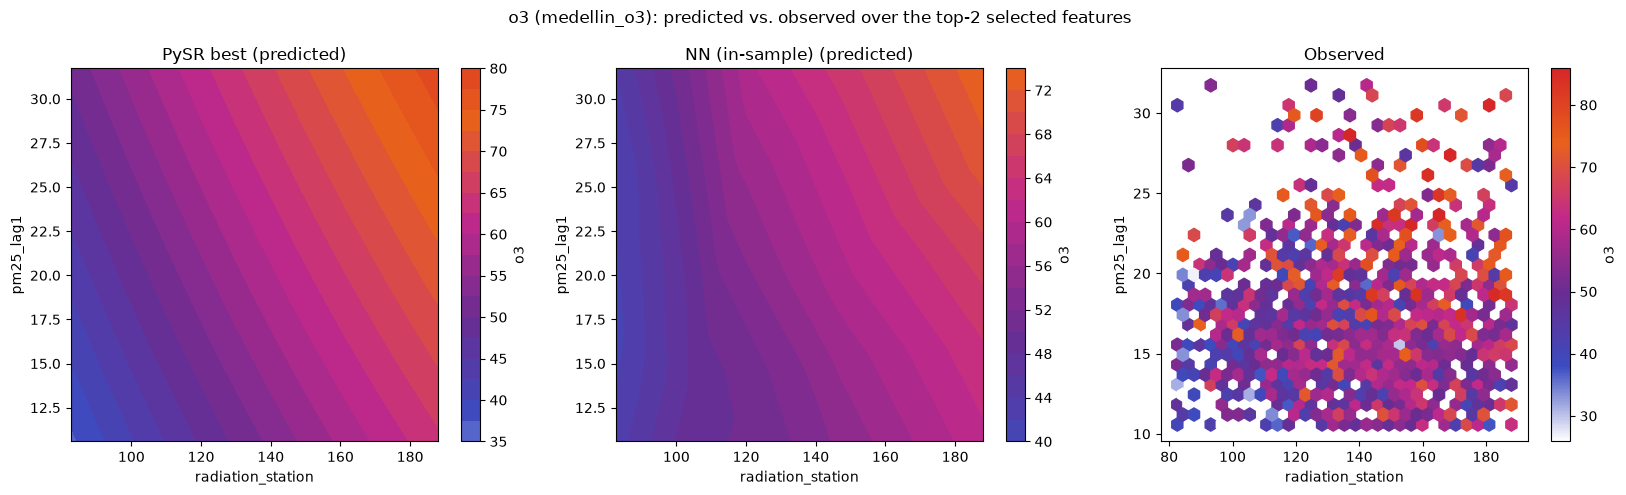

In [11]:

from common.feature_selection import nn_in_sample_model
stratified_error_table(y_true_loyo, y_pred_loyo, unit="")

scaler_full, nn_full, _, _ = nn_in_sample_model(data_with_year, features, target='o3')

fig = response_surface_comparison(
    data=data,
    features=features,
    target='o3',
    predict_fns={
        "PySR best": lambda Xg: sr_model.predict(Xg, index=best_idx),
        "NN (in-sample)": lambda Xg: nn_full.predict(scaler_full.transform(Xg)),
    },
    title="o3 (medellin_o3): predicted vs. observed over the top-2 selected features",
)
fig.savefig(FIG_DIR / "medellin_o3_response_surface.png", dpi=150)
plt.show()


## Predicted vs. observed (1:1 scatter)

Mirrors Abramian et al. (2025, npj Climate and Atmospheric Science) Fig. 3A/B: a
density-colored one-to-one scatter, one panel per model, with the 1:1 line drawn
explicitly. Complements the response-surface plot above (which shows bias as a function
of feature space) with the more fundamental view -- bias in prediction space itself,
independent of which feature is responsible.

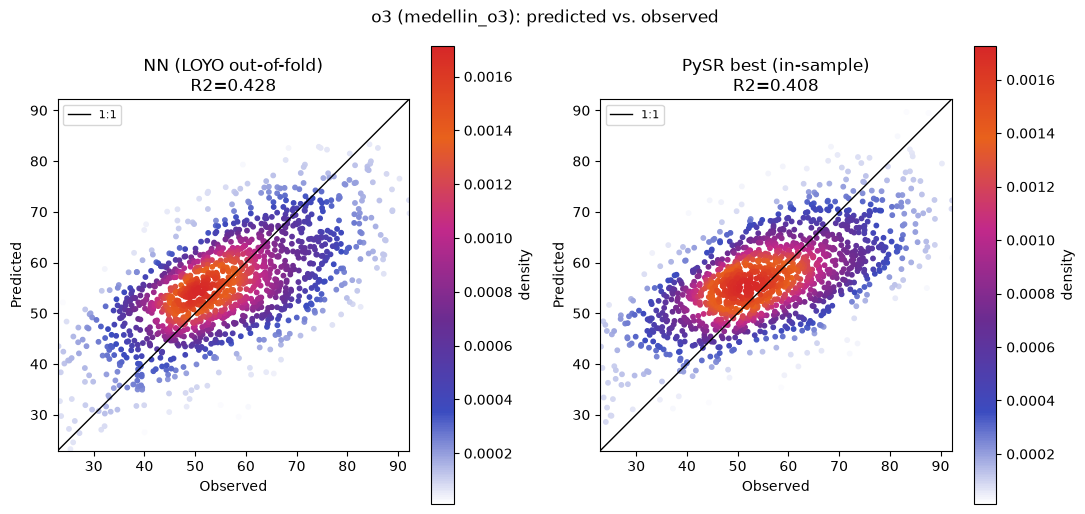

In [12]:

pysr_best_pred = sr_model.predict(X, index=best_idx)
fig2 = predicted_vs_observed(
    {
        "NN (LOYO out-of-fold)": (y_true_loyo, y_pred_loyo),
        "PySR best (in-sample)": (y, pysr_best_pred),
    },
    unit="",
    title="o3 (medellin_o3): predicted vs. observed",
)
fig2.savefig(FIG_DIR / "medellin_o3_pred_vs_obs.png", dpi=150)
plt.show()


## Categorical (HIT/FAR/CSI) verification and per-term decomposition

Standard forecast-verification framing (does the equation actually flag the worst
days, not just get the average day roughly right), plus a term-by-term breakdown of
the sparsest pySINDy fit -- since its polynomial form is a literal sum of
coefficient*term, each term's contribution to the prediction can be isolated directly.
A term's fitted coefficient sign can differ from its own raw correlation with the
target when terms are collinear -- a real multicollinearity effect, flagged rather than
silently trusted as "the" physical sign.

Categorical (HIT/FAR/CSI) verification, event = exceeds observed Nth percentile:
               threshold_value  n_events   TP   FN  FP    TN  hit_rate    far    csi
threshold_pct                                                                       
75                      65.145       348  141  207  76   965     0.405  0.350  0.333
90                      74.639       139   32  107  18  1232     0.230  0.360  0.204
95                      80.395        70   11   59   5  1314     0.157  0.312  0.147
=== pySINDy term decomposition ===
Per-term contribution breakdown (3 active terms):
        term   coef  mean_abs_contribution  std_contribution  corr_with_target
  wind_speed 27.494                 36.204             8.308             0.098
           1 35.540                 35.540             0.000               NaN
wind_speed^2 -8.709                 15.896             6.962            -0.090


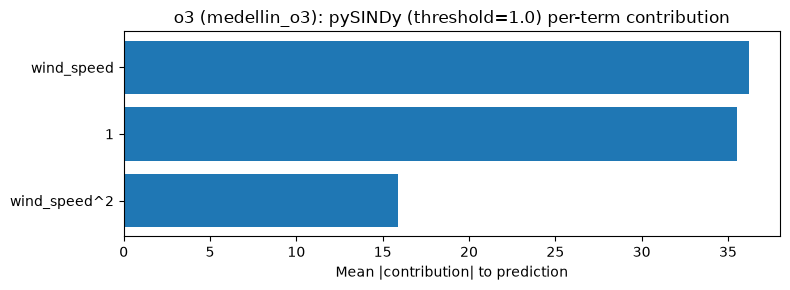


=== PySR best-plausible equation: feature usage + term decomposition ===
Selected but NOT present in this equation: ['pmc_lag2']
PySR equation per-term contribution (2 top-level terms):
                                                                                                                              term  mean_abs_contribution  std_contribution  corr_with_target
sqrt(sqrt(38.324894*no2 + 38.324894*pm25_lag1)*(pm25_lag1 + radiation_station - wind_speed*(no_sisaire + wind_speed - 38.324894)))                 84.473            11.710             0.552
                                                                                              wind_speed*(-wind_speed - 19.785572)                 27.879             6.772            -0.097


/var/folders/30/gtfddbxx5z3f_hc8v4br4pkh0000gn/T/ipykernel_54508/3844936075.py:135: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


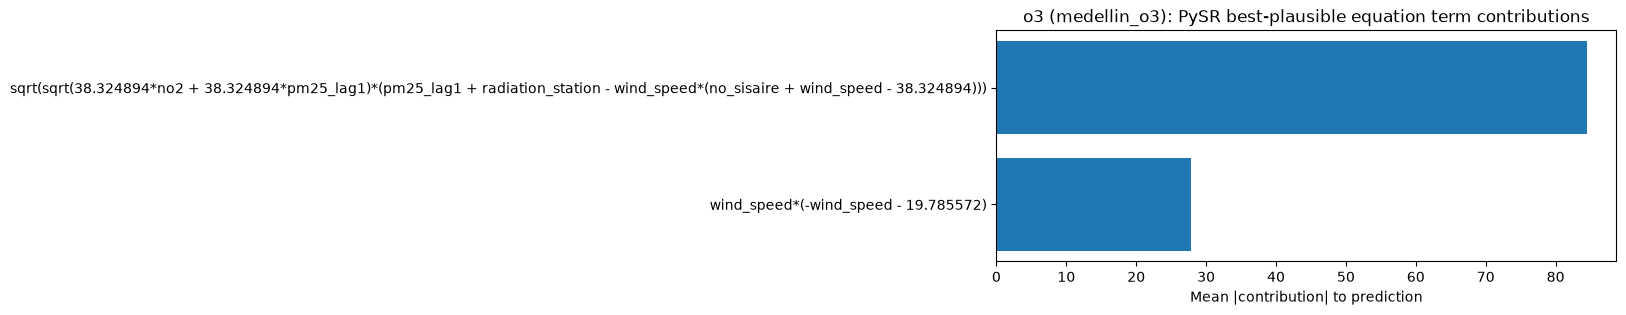

In [13]:

hit_far_table(y_true_loyo, y_pred_loyo)

# pySINDy decomposition (sparsest fit) -- note this can structurally MISS a real,
# nonlinearly-related feature (e.g. a right-skewed fire-hotspot count needs a sqrt
# transform pySINDy's plain polynomial library doesn't try), so always check features
# actually present in the equation below rather than trusting this list as complete.
sparsest_thresh = thresholds[-1]
sparsest_model, _ = sindy_models[sparsest_thresh]
print("=== pySINDy term decomposition ===")
term_summary, term_fig = sindy_term_contributions(
    sparsest_model, lib_X, lib_names, y,
    title=f"o3 (medellin_o3): pySINDy (threshold={sparsest_thresh}) per-term contribution",
)
term_fig.savefig(FIG_DIR / "medellin_o3_term_contributions.png", dpi=150)
plt.show()

# Which selected features actually made it into the reported PySR equation, and a
# top-level additive decomposition of that equation (may not isolate every feature if
# it's nested inside a product rather than a top-level sum -- see markdown above).
best_eq_str = best_plausible.iloc[-1]['equation'] if len(best_plausible) else sr_model.equations_.iloc[-1]['equation']
print()
print("=== PySR best-plausible equation: feature usage + term decomposition ===")
check_features_used(best_eq_str, features)
pysr_summary, pysr_fig = pysr_term_contributions(
    best_eq_str, features, data, y,
    title=f"o3 (medellin_o3): PySR best-plausible equation term contributions",
)
pysr_fig.savefig(FIG_DIR / "medellin_o3_pysr_term_contributions.png", dpi=150)
plt.show()


## Save results

In [14]:
sr_model.equations_.to_csv(DATA_DIR / "medellin_o3_pysr_pareto_front.csv", index=False)
print("Saved PySR Pareto front and baseline R2 =", baseline_r2)


Saved PySR Pareto front and baseline R2 = 0.05866910701402195
